In [1]:
import numpy as np
import pandas as pd
import h5py
import os
import sys

import matplotlib.pyplot as plt

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits

from scipy import stats

In [2]:
from astropy.cosmology import FlatLambdaCDM 
from astropy.cosmology import z_at_value
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)

In [3]:
"""
plot_style.py
-------------
Master matplotlib/plotly style loader.
Usage:
    from plot_style import *
    from plot_style import get_n_colors, MidFactor
"""

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import ScalarFormatter, LogLocator
from matplotlib.colors import to_rgba
from matplotlib.gridspec import GridSpec
import matplotlib.patheffects as path_effects
import plotly.graph_objects as go
from matplotlib.lines import Line2D
import matplotlib.patches as Patches
from matplotlib.legend_handler import HandlerTuple
import matplotlib.patheffects as pe

# ── RC Params ─────────────────────────────────────────────────────────────────
params = {
        # Font
        "font.family":          "serif",
        "font.size":            24,
        "text.usetex":          True,

        # Tick labels
        "xtick.labelsize":      20,
        "ytick.labelsize":      20,

        # Tick direction & size
        "xtick.direction":      "in",
        "ytick.direction":      "in",
        "xtick.major.size":     7,
        "ytick.major.size":     7,
        "xtick.minor.size":     3.5,
        "ytick.minor.size":     3.5,
        "xtick.minor.visible":  False,
        "ytick.minor.visible":  False,

        # Tick padding & axes
        "xtick.major.pad":      7,
        "axes.linewidth":       2.0,

        # tight layout
        "figure.constrained_layout.use": True
    }

plt.rcParams.update(params)


In [4]:
# ── Helpers ───────────────────────────────────────────────────────────────────

# Source - https://stackoverflow.com/a/49601444
# Posted by Ian Hincks, modified by community. See post 'Timeline' for change history
# Retrieved 2026-07-08, License - CC BY-SA 4.0

def lighten_color(color, amount=0.5):
    """
    Lightens the given color by multiplying (1-luminosity) by the given amount.
    Input can be matplotlib color string, hex string, or RGB tuple.

    Examples:
    >> lighten_color('g', 0.3)
    >> lighten_color('#F034A3', 0.6)
    >> lighten_color((.3,.55,.1), 0.5)
    """
    import matplotlib.colors as mc
    import colorsys
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    return colorsys.hls_to_rgb(c[0], 1 - amount * (1 - c[1]), c[2])

def get_n_colors(n, cmap_name="viridis"):
    """Sample n evenly-spaced colours from a matplotlib colormap."""
    cmap = plt.get_cmap(cmap_name)
    return [cmap(i / max(n - 1, 1)) for i in range(n)]


def MidFactor(n):
    """Return the middle divisor of n (useful for subplot grid layout)."""
    divisors = [i for i in range(1, n + 1) if n % i == 0]
    return divisors[len(divisors) // 2]

# Arrow plot
import matplotlib.path as mpath
def up_arrow_marker():
    Path = mpath.Path
    verts = [
        (0.0, 0.0),        
        (-0.03, 0.0),      
        (-0.28, -0.27),     
        (-0.21, -0.35),    
        (-0.06, -0.2), 
        (-0.06, -1.0),
        (0.06, -1.0),
        (0.06, -0.2), 
        (0.21, -0.35),
        (0.28, -0.27),
        (0.03, 0.0),
        (0.0, 0.0)
    ]
    codes = [Path.MOVETO] + [Path.LINETO]*10 + [Path.CLOSEPOLY]
    return Path(verts, codes)

def down_arrow_marker():
    Path = mpath.Path
    verts = [
        (0.0, 0.0),        # Tip
        (-0.3, 0.3),       # Left of arrowhead
        (-0.05, 0.3),      # Left shaft edge
        (-0.05, 1.0),      # Shaft top left
        (0.05, 1.0),       # Shaft top right
        (0.05, 0.3),       # Right shaft edge
        (0.3, 0.3),        # Right of arrowhead
        (0.0, 0.0),        # Close shape at tip
    ]
    codes = [mpath.Path.MOVETO] + [mpath.Path.LINETO]*6 + [mpath.Path.CLOSEPOLY]

    verts = [
        (0.0, 0.0),        
        (-0.03, 0.0),      
        (-0.28, 0.27),     
        (-0.21, 0.35),    
        (-0.06, 0.2), 
        (-0.06, 1.0),
        (0.06, 1.0),
        (0.06, 0.2), 
        (0.21, 0.35),
        (0.28, 0.27),
        (0.03, 0.0),
        (0.0, 0.0)
    ]
    codes = [Path.MOVETO] + [Path.LINETO]*10 + [Path.CLOSEPOLY]
    
    return Path(verts, codes)

up_arrow_marker = up_arrow_marker()
down_arrow_marker = down_arrow_marker()

grid_alpha = 0.1
grid_color = 'grey'
grid_ls = "-"

# Load in things

In [5]:
h5file = "/Users/jordan/Documents/Epochs/data/analysis_data.h5"
filters_info = pd.read_csv("/Users/jordan/Documents/Epochs/data/throughputs/wavelengths.txt", delimiter=" ")

In [6]:
# number counts 
smiles_number_counts = pd.read_hdf(h5file, "number_counts/smiles")
midis_number_counts = pd.read_hdf(h5file, "number_counts/midis")

smiles_frame_stats = pd.read_hdf(h5file, "frame_stats/smiles")
midis_frame_stats = pd.read_hdf(h5file, "frame_stats/midis")

In [122]:

# prospect_with_agn = pd.read_csv(
#     "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_fritz_norm_eazy_no_tau_birth_astro_cat.csv"
# )
# prospect_without_agn = pd.read_csv(
#     "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_norm_eazy_no_tau_birth_astro_cat.csv"
# )
# prospect_lrd = pd.read_csv(
#     "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_LRDLIU_norm_eazy_no_tau_birth_lrd_astro_cat.csv"
# )
prospect_robust = pd.read_csv(
    "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_fritz_robust_catalogue.csv"
)
# prospect_sample_photom = pd.read_csv(
#     "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_fritz_robust_fit_photom.csv"
# )
BHAR_SFR = pd.read_csv(
    "/Users/jordan/Documents/Epochs/data/prospect/prospect_robust_BHAR_SFR_ratio.csv"
)

In [123]:
# lbt_bins = np.arange(8.0, 13.5, 0.5)
lbt_bins = np.append(np.arange(8.0, 13.0, 0.5), [13])
zbins = z_at_value(cosmo.lookback_time, lbt_bins*u.Gyr).value
# zbins = np.append(z_at_value(cosmo.lookback_time, lbt_bins*u.Gyr).value, [7,9,11])
zmids = zbins[:-1] + np.diff(zbins)/2.0

sample_idx = (prospect_robust['zQ50'] >= zbins[0]) & (prospect_robust['zQ50'] < zbins[-1])
quenched_idx = prospect_robust["SFR10Q50"][sample_idx]/prospect_robust["StellarMassQ50"][sample_idx] <= 0.2/(1e9*cosmo.age(prospect_robust["zQ50"][sample_idx]).value) # probably just use this for upper limits on the SFR10 plots 

prospect_sample = prospect_robust[sample_idx]
BHAR_SFR_sample = BHAR_SFR[sample_idx]
# prospect_sample_photom = prospect_robust_photom[sample_idx]

starforming_sample = prospect_robust[sample_idx][~quenched_idx] 
quenched_sample = prospect_robust[sample_idx][quenched_idx] # for upper limits
minimum_SFR10_vals = quenched_sample["StellarMassQ50"] * 0.2/(1e9*cosmo.age(quenched_sample["zQ50"]).value)

# constants 
LAGN2BHAR = ( 3.154e7 * 1e-7 * (0.1 * 3e8**2)**-1 / 2e30)

# Number counts

In [19]:
stone25 = pd.read_csv(
    os.path.expanduser("~/Documents/Epochs/data/literature/number_counts/stone25.csv")
)

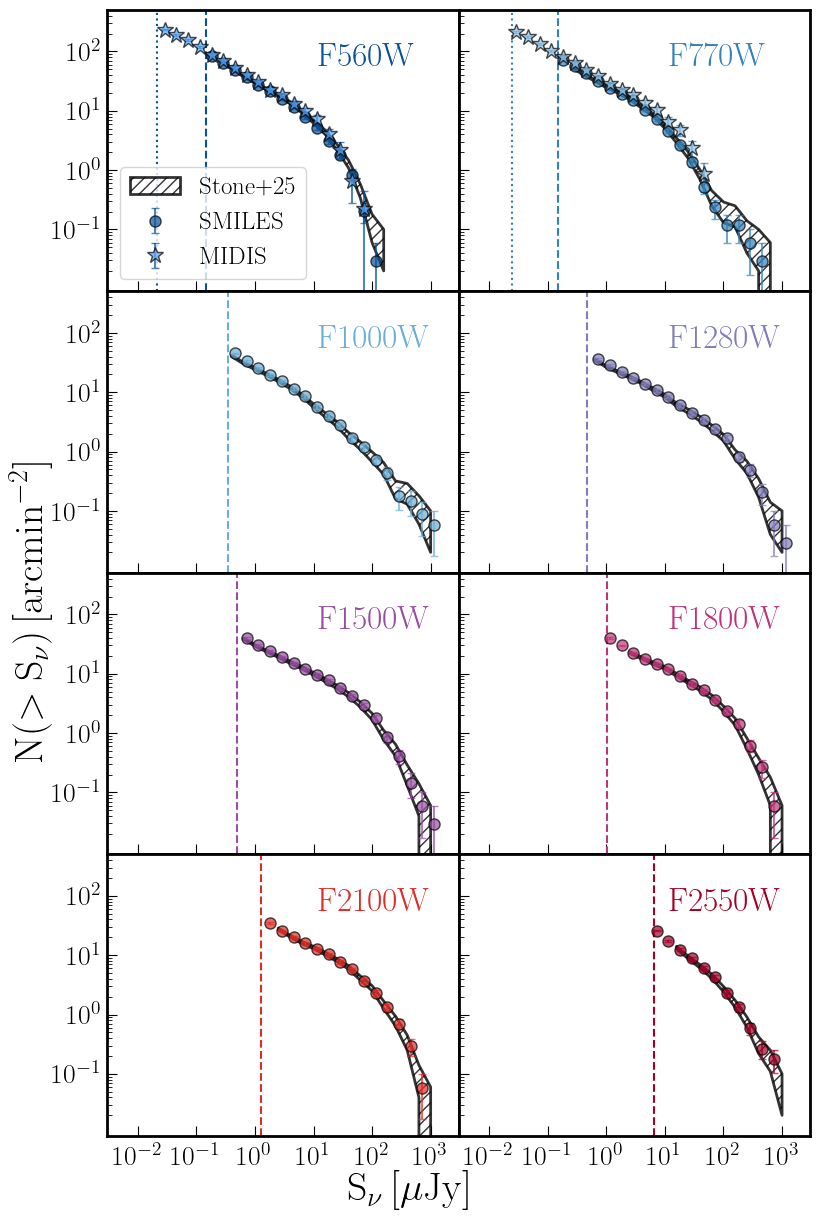

In [20]:
MIRI_keys = ["F560W", "F770W", "F1000W", "F1280W", "F1500W", "F1800W", "F2100W", "F2550W"]
cols = [
  "#2166AC",  # deep blue
  "#4393C3",  # mid blue
  "#92C5DE",  # light blue
  "#EDF176",  # pale yellow-orange
  "#F4A736",  # yellow-orange
  "#E8601C",  # orange
  "#D6301F",  # red-orange
  "#A50026"   # deep red
]
cols = ("#08519C", "#3182BD", "#6BAED6", "#807DBA",
          "#984EA3", "#C0357A", "#DE2D26", "#A50026")

fig, ax = plt.subplots(ncols=2, nrows = 4, sharex = True, sharey = True, figsize = (8,12))
ax = ax.flatten()

fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

for i, axx in enumerate(ax):
    axx.errorbar(
        smiles_number_counts["uJy_mids"],
        smiles_number_counts[f"{MIRI_keys[i]}_cumul"],
        yerr = smiles_number_counts[f"{MIRI_keys[i]}_cumulerr"],
        capsize = 3,
        fmt = "o",
        markersize = 8,
        markeredgecolor = "black",
        markerfacecolor = cols[i],
        ecolor = cols[i],
        alpha = 0.7, 
        label = "SMILES"
    )
    axx.axvline(
        smiles_frame_stats[f"{MIRI_keys[i]}_5sigma_depth_32asec"].values/1e-6,
        color = cols[i],
        ls = "--"
    )
    if i < 2:
        axx.errorbar(
            midis_number_counts["uJy_mids"],
            midis_number_counts[f"{MIRI_keys[i]}_cumul"],
            yerr = midis_number_counts[f"{MIRI_keys[i]}_cumulerr"],
            capsize = 3,
            fmt = "*",
            markersize = 12,
            markerfacecolor = lighten_color(cols[i], amount= 0.5) ,
            markeredgecolor = "black",
            ecolor = cols[i],
            alpha = 0.7,
            label = "MIDIS"
        )
        axx.axvline(
            midis_frame_stats[f"{MIRI_keys[i]}_5sigma_depth_32asec"].values/1e-6,
            color = cols[i],
            ls = ":"
        )

    if i == 1:
        axx.fill_between(
        # -2.5*np.log10(stone25["Flux_uJy"])+23.9,
        stone25["Flux_uJy"],
        stone25[f"{MIRI_keys[i]}_SMILES"] - stone25[f"{MIRI_keys[i]}_SMILES_err"],
        stone25[f"{MIRI_keys[i]}_SMILES"] + stone25[f"{MIRI_keys[i]}_SMILES_err"],
        facecolor = "none",
        hatch = "///",
        edgecolor = "black",
        alpha = 0.8,
        lw = 2
    )
    else:
        axx.fill_between(
            # -2.5*np.log10(stone25["Flux_uJy"])+23.9,
            stone25["Flux_uJy"],
            stone25[f"{MIRI_keys[i]}"] - stone25[f"{MIRI_keys[i]}_err"],
            stone25[f"{MIRI_keys[i]}"] + stone25[f"{MIRI_keys[i]}_err"],
            facecolor = "none",
            hatch = "///",
            edgecolor = "black",
            alpha = 0.8,
            lw = 2,
            label = "Stone+25"
        )
    axx.text(
        0.6,
        0.8,
        MIRI_keys[i],
        transform = axx.transAxes,
        color = cols[i]
        # path_effects = [pe.Stroke(linewidth=2, foreground='black'), pe.Normal()]
    )

ax[0].legend(
    frameon = True,
    fontsize = 18,
    loc = "lower left"
)
ax[0].set_xscale("log")
ax[0].set_yscale("log")

# ax[0].set_xlim([29, 15])
ax[0].set_xlim([3e-3, 3e3])
ax[0].set_ylim([9e-3, 5e2])

# ax[0].set_xticks([28, 24, 20, 16])
ax[0].set_xticks([1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3])
ax[0].set_yticks([1e-1, 1e0, 1e1, 1e2])

fig.supxlabel(r"$\mathrm{S_{\nu} \, [\mu Jy}]$")
fig.supylabel(r"$\mathrm{N(>S_{\nu}) \, [arcmin^{-2}]}$")

plt.savefig(
    "/Users/jordan/Documents/Epochs/plots/number_counts.pdf", 
    bbox_inches="tight", 
    dpi = 240
)


# Compare EAZY specz and photoz

In [9]:
def compute_sigmaNMAD(zspec, zphot, zphot_lim=0):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    idx = (zphot > zphot_lim) & (~np.isnan(zphot))
    deltaz = zphot[idx] - zspec[idx]
    
    sigmaNMAD = 1.48 * np.median(np.abs((deltaz - np.median(deltaz)) / (1 + zspec[idx])))
    return sigmaNMAD


def compute_outliers(zspec, zphot, thresh=0.15, zphot_lim=-2):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    idx = (zphot > zphot_lim) & (~np.isnan(zphot))
    deltaz = np.abs(zphot[idx] - zspec[idx])
    
    Noutlier = np.sum(deltaz / (1 + zspec[idx]) > thresh)
    outlier_frac = Noutlier / len(zspec[idx])
    
    print(f"Noutlier: {Noutlier}")
    print(f"N total:  {len(zspec[idx])}")
    
    return outlier_frac, deltaz / (1 + zspec[idx]) > thresh

In [10]:
jades_specz = pd.read_hdf(
    h5file, 
    "specz/jades_match/specz"
)
agn_blue_eazy_spec_stats = pd.read_hdf(
    h5file, 
    "specz/jades_match/agn_blue_sfhz_stats"
)
agn_blue_eazy_stats = pd.read_hdf(
    h5file, 
    "eazy/eazy_stats/agn_blue_sfhz"
)

juodzbalis26_match = pd.read_hdf(
    h5file, 
    "specz/juodzbaliz_match/specz"
)
prospect_juodzbalis26_match = pd.read_hdf(
    h5file, 
    "specz/juodzbaliz_match/prospect_with_agn"
)

/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/tables/path.py:146: NaturalNameWarning: object name is not a valid Python identifier: 'object_id.1'; it does not match the pattern ``^[a-zA-Z_][a-zA-Z0-9_]*$``; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/tables/path.py:146: NaturalNameWarning: object name is not a valid Python identifier: 'category.1'; it does not match the pattern ``^[a-zA-Z_][a-zA-Z0-9_]*$``; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/tables/path.py:146: NaturalNameWarning: object name is not a valid Python identifier: 'ID.1'; it does not match the pattern ``^[a-zA-Z_][a-zA-Z0-9_]*$``; you will not be able to use natural naming to access

Noutlier: 2
N total:  134


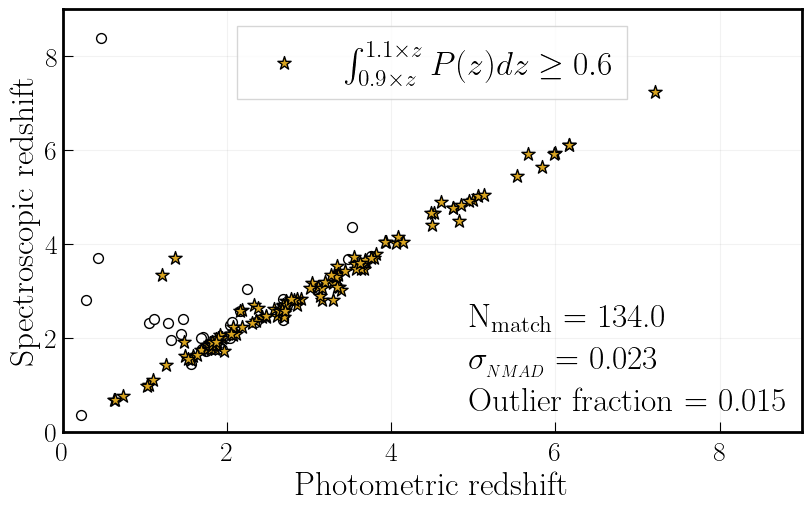

In [137]:
fig, ax = plt.subplots(1,1, figsize = (8,5))
ax = [ax]
ax[0].scatter(
    agn_blue_eazy_spec_stats["z_ml"][~(agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60)],
    jades_specz["z_Spec"][~(agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60)],
    edgecolor = 'black',
    facecolor = 'white',
    s = 50
)
ax[0].scatter(
    agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60],
    jades_specz["z_Spec"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60],
    edgecolor = 'black',
    facecolor = 'goldenrod',
    marker = "*",
    s = 100,
    label = r"$\int^{1.1 \times z}_{0.9 \times z} P(z)dz \geq 0.6$"
)

ax[0].text(
    0.55, 0.25, 
    rf"N$_{{\mathrm{{match}}}}$ =  {len(agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60]):.1f}", transform=ax[0].transAxes
)
ax[0].text(
    0.55, 0.15, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=jades_specz["z_Spec"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60], zphot=agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60]):.3f}", transform=ax[0].transAxes
)
ax[0].text(
    0.55, 0.05, 
    rf"Outlier fraction = {compute_outliers(zspec=jades_specz["z_Spec"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60], zphot=agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60])[0]:.3f}", transform=ax[0].transAxes
)

ax[0].set_xlim([0,9])
ax[0].set_ylim([0,9])

ax[0].set_xlabel("Photometric redshift")
ax[0].set_ylabel("Spectroscopic redshift")

ax[0].grid(grid_ls, color = grid_color, alpha = grid_alpha)
ax[0].legend(fancybox = False)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/jades_specz.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


# Redshift distribution

## Redshift histogram

Text(0, 0.5, '$\\mathrm{N_{AGN} / N_{Total}}$')

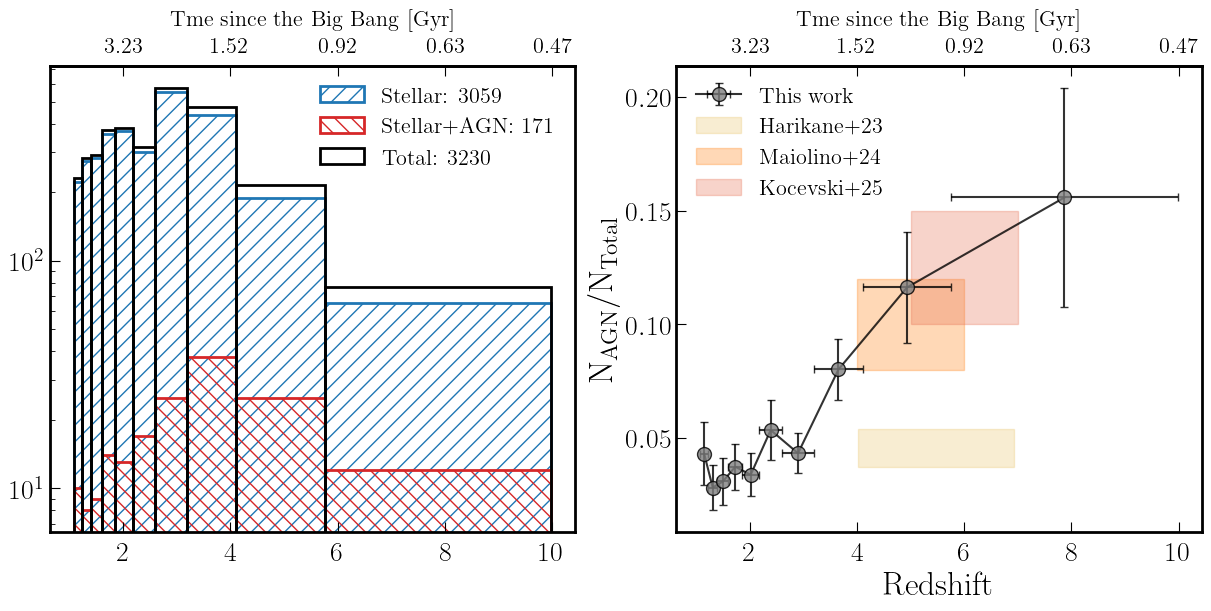

In [114]:
fig, ax = plt.subplots(1,2, figsize = (12,6), layout = 'constrained')
stellar_counts, stellar_bin_edges, stellar_patches = ax[0].hist(
    prospect_sample["zQ50"][prospect_sample["FitType"] == "Stellar"], 
    facecolor = "none",
    edgecolor = "tab:blue", 
    hatch = "//", 
    bins=zbins, 
    label = f"Stellar: {np.sum(prospect_sample["FitType"] == "Stellar")}",
    lw = 2.0
)
stellarAGN_counts, stellarAGN_bin_edges, stellarAGN_patches = ax[0].hist(
    prospect_sample["zQ50"][prospect_sample["FitType"] == "StellarAGN"], 
    facecolor = "none",
    edgecolor = "tab:red", 
    hatch = "\\\\", 
    bins=zbins, 
    label = f"Stellar+AGN: {np.sum(prospect_sample["FitType"] == "StellarAGN")}",
    lw = 2.0
)
tot_counts, tot_bin_edges, tot_patches = ax[0].hist(
    prospect_sample["zQ50"], 
    facecolor = "none",
    edgecolor = "black", 
    # hatch = "\\//",
    # alpha = 0.4, 
    bins=zbins,
    lw = 2,
    label = f"Total: {len(prospect_sample)}",
)

ax[0].legend(
    frameon = False,
    fontsize = 16
)

stellarAGN_err = np.sqrt(stellarAGN_counts)
tot_err = np.sqrt(tot_counts)
ratio_err = stellarAGN_counts/tot_counts * np.sqrt((stellarAGN_err / stellarAGN_counts)**2 + (tot_err / tot_counts)**2)

thiswork_ = ax[1].errorbar(
    zmids, 
    stellarAGN_counts/tot_counts, 
    xerr = [np.diff(zbins)*0.5],
    yerr = [ratio_err],
    marker = "o", 
    markersize = 10,
    markerfacecolor = "grey",
    markeredgecolor = "black",
    color = "black",
    ecolor = "black", 
    alpha = 0.8,
    capsize = 3,
    label = "This work"
)

harikane23_AGNfrac = Patches.Rectangle(
    xy = (4.015, 0.037),
    width = 2.921,
    height = 0.017,
    alpha = 0.3,
    color = "#e9c46a",
    label = "Harikane+23"
)
maiolino24_AGNfrac = Patches.Rectangle(
    xy = (4.0, 0.08),
    width = 2.0,
    height = 0.04,
    alpha = 0.3,
    color = "tab:orange",
    label = "Maiolino+24"
)
kocevski25_AGNfrac = Patches.Rectangle(
    xy = (5.0, 0.1),
    width = 2.0,
    height = 0.05,
    alpha = 0.3,
    color = "#e76f51",
    label = "Kocevski+25"
)
harikane23_AGNfrac_ = ax[1].add_patch(harikane23_AGNfrac)
maiolino24_AGNfrac_ = ax[1].add_patch(maiolino24_AGNfrac)
kocevski25_AGNfrac_ = ax[1].add_patch(kocevski25_AGNfrac)

ax[1].legend(
    handles = (thiswork_, harikane23_AGNfrac_, maiolino24_AGNfrac_, kocevski25_AGNfrac_),
    loc = "upper left",
    fontsize = 16,
    frameon = False,
    ncol = 1,
    framealpha = 0.5
)

ax[0].set_yscale("log")
# ax[0].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
# ax[0].set_xticks([2.0, 4.0, 6.0, 8.0, 10.0, 12])
# ax[0].set_xlabel("Redshift")
# ax[0].set_ylabel("Frequency")

# ax[1].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
# ax[1].set_xticks([2.0, 4.0, 6.0, 8.0, 10.0, 12])
# ax[1].set_ylim([0, 0.17])
# ax[1].set_yticks([0.0, 0.05, 0.10, 0.15])

for axx in ax:
    ax_top = axx.secondary_xaxis('top')
    ax_top.set_xticks([2.0, 4.0, 6.0, 8.0, 10.0])
    ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age([2.0, 4.0, 6.0, 8.0, 10.0]).value], fontsize = 16)
    ax_top.set_xlabel("Tme since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

ax[1].set_xlabel("Redshift")
ax[1].set_ylabel(r"$\mathrm{N_{AGN} / N_{Total}}$")

# plt.savefig("/Users/jordan/Documents/Epochs/plots/redshift_hist.pdf",     bbox_inches="tight", dpi = 240)

## Vs. redshift distributions

In [10]:
def vs_dist_plot_errorbar(ax, z, x, zerr_lo, zerr_hi, xerr_lo, xerr_hi, cols, marker = "o", markersize = 8):
    for zz, xx, zz_lo, zz_hi, xx_lo, xx_hi, cc in zip(z, x, zerr_lo, zerr_hi, xerr_lo, xerr_hi, cols):
        ax.errorbar(
            zz, 
            xx, 
            xerr = [[zz_lo], [zz_hi]],
            yerr = [[xx_lo], [xx_hi]],
            ls = 'none',
            marker = marker, 
            markersize = markersize,
            markerfacecolor = cc,
            markeredgecolor = lighten_color(cc, 1.5),
            ecolor = lighten_color(cc, 1.5), 
            alpha = 0.4,
            capsize = 3
    )

Text(0.5, 0.01, 'Redshift')

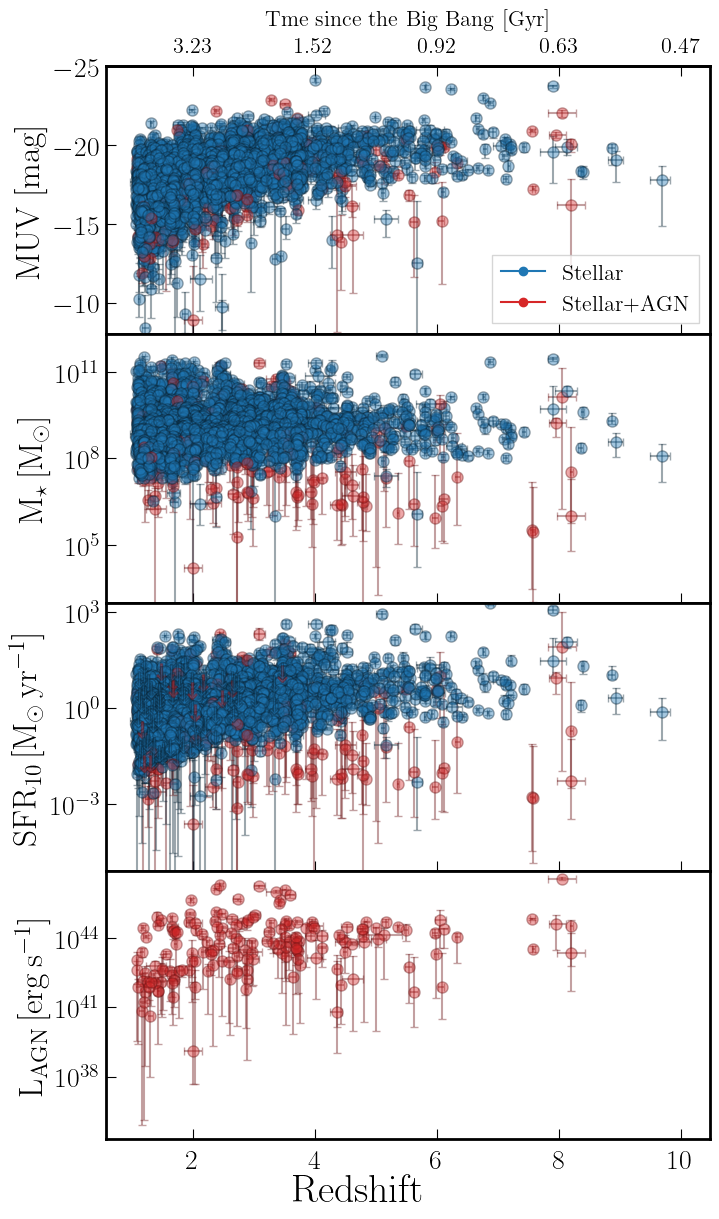

In [107]:
cols = ["tab:blue" if x == "Stellar" else "tab:red" for x in prospect_sample['FitType']]

fig, ax = plt.subplots(4, 1, figsize = (7,12), layout = 'constrained', sharex = True)
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

vs_dist_plot_errorbar(
    ax[0],
    prospect_sample["zQ50"], 
    prospect_sample["UV1500Q50"], 
    prospect_sample["z_lo"], 
    prospect_sample["z_hi"],
    prospect_sample["UV1500_lo"], 
    prospect_sample["UV1500_hi"],
    cols
)
ax[0].set_ylim([-8, -25])

vs_dist_plot_errorbar(
    ax[1],
    prospect_sample["zQ50"], 
    prospect_sample["StellarMassQ50"], 
    prospect_sample["z_lo"], 
    prospect_sample["z_hi"],
    prospect_sample["StellarMass_lo"], 
    prospect_sample["StellarMass_hi"],
    cols
)
ax[1].set_yscale('log')
ax[1].set_ylim([1e3, 2e12])

vs_dist_plot_errorbar(
    ax[2],
    starforming_sample["zQ50"], 
    starforming_sample["SFR10Q50"], 
    starforming_sample["z_lo"], 
    starforming_sample["z_hi"],
    starforming_sample["SFR10_lo"], 
    starforming_sample["SFR10_hi"],
    ["tab:blue" if x == "Stellar" else "tab:red" for x in starforming_sample['FitType']]
)
vs_dist_plot_errorbar(
    ax[2],
    quenched_sample["zQ50"], 
    # 1e-5*np.ones(len(quenched_sample["zQ50"])), 
    minimum_SFR10_vals,
    quenched_sample["z_lo"], 
    quenched_sample["z_hi"],
    minimum_SFR10_vals*0.0, 
    minimum_SFR10_vals*0.0,
    ["tab:blue" if x == "Stellar" else "tab:red" for x in quenched_sample['FitType']],
    marker=down_arrow_marker,
    markersize=8*3.0
)
ax[2].set_yscale('log')
ax[2].set_ylim([8e-6, 2e3])

vs_dist_plot_errorbar(
    ax[3],
    prospect_sample["zQ50"], 
    prospect_sample["AGNlumQ50"], 
    prospect_sample["z_lo"], 
    prospect_sample["z_hi"],
    prospect_sample["AGNlum_lo"], 
    prospect_sample["AGNlum_hi"],
    cols
)
ax[3].set_yscale('log')
ax[3].set_ylim([2e35, 8e46])

ax[0].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
# ax[0].set_xlim([-0.5, zbins[-1]+0.5])

ax[0].set_ylabel("MUV [mag]")
ax[1].set_ylabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
ax[2].set_ylabel(r"$\mathrm{SFR_{10} \, [M_{\odot} \, yr^{-1}]}$")
ax[3].set_ylabel(r"$\mathrm{L_{AGN} \, [erg \, s^{-1}]}$")

ax_top = ax[0].secondary_xaxis('top')
ax_top.set_xticks(ax[0].get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax[0].get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Tme since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

custom_lines = [Line2D([0], [0], color="tab:blue", marker = "o"),
                Line2D([0], [0], color="tab:red", marker = "o")]
ax[0].legend(custom_lines, ["Stellar", "Stellar+AGN"], fontsize = 16, fancybox = False)

fig.supxlabel("Redshift")

# fig.savefig(
#     "/Users/jordan/Documents/Epochs/plots/astro_quantities_vs_redshift.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# SFR-Mstar

Text(0.02, 0.5, '$\\mathrm{SFR_{10} \\, [M_{\\odot} \\, yr^{-1}]}$')

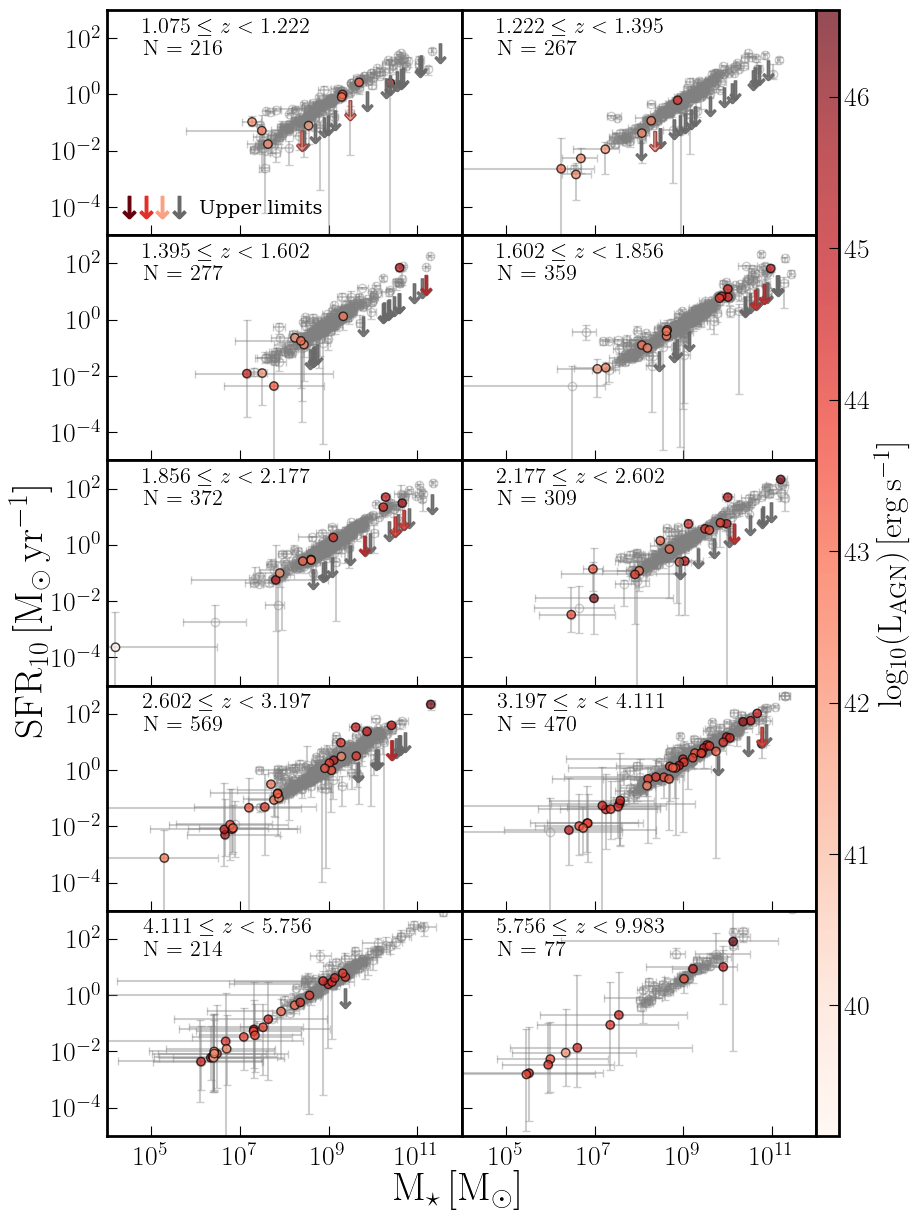

In [108]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

tot_agnlum = prospect_sample["AGNlumQ50"]

for i in range(len(zmids)):
    zidx = (starforming_sample["zQ50"] >= zbins[i]) & (starforming_sample["zQ50"] < zbins[i+1])
    zidx_quenched = (quenched_sample["zQ50"] >= zbins[i]) & (quenched_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR10Q50"][zidx],
        xerr = [starforming_sample["StellarMass_lo"][zidx], starforming_sample["StellarMass_hi"][zidx]],
        yerr = [starforming_sample["SFR10_lo"][zidx], starforming_sample["SFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR10Q50"][zidx],
        c = np.log10(starforming_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        # vmin = 41,
        # vmax = 47,
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.7
    )

    quench_ = ax[i].scatter(
        quenched_sample["StellarMassQ50"][zidx_quenched],
        minimum_SFR10_vals[zidx_quenched],
        zorder = 100, 
        color='dimgrey',
        alpha = 0.9,
        marker = down_arrow_marker,
        edgecolor = "dimgrey",
        s = 800
    )
    sc_quenched_ = ax[i].scatter(
        quenched_sample["StellarMassQ50"][zidx_quenched],
        minimum_SFR10_vals[zidx_quenched],
        c = np.log10(quenched_sample["AGNlumQ50"][zidx_quenched]),
        # vmin = 41,
        # vmax = 47,
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.7,
        marker = down_arrow_marker,
        edgecolor = "firebrick",
        s = 800
    )
    
    # print((minimum_SFR10_vals[zidx_quenched]).tolist())
    # print((np.log10(quenched_sample["StellarMassQ50"][zidx_quenched])).tolist())
    # print(len(quenched_sample["StellarMassQ50"][zidx_quenched]))

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        f"N = {sum(zidx)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([1e-5, 1e3])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# cbar_ax = fig.add_axes([0.87, 0.05, 0.02, 0.9])  # [left, bottom, width, height]

plt.rcParams["text.usetex"] = False
custom_lines = [
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[3],
           marker='$\u2193$', markersize=8*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[2],
           marker='$\u2193$', markersize=8*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[1],
           marker='$\u2193$', markersize=8*2, linestyle='None'),
    Line2D([0], [0], color="dimgrey",
           marker='$\u2193$', markersize=8*2, linestyle='None'),
]
ax[0].legend(
    [tuple(custom_lines)],
    ["Upper limits"],
    fontsize=14,
    frameon=False,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    handlelength=3,   # widen the entry so 3 markers don't overlap/crowd
    loc = "lower left"
)
plt.rcParams["text.usetex"] = True

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR_{10} \, [M_{\odot} \, yr^{-1}]}$")

# fig.savefig(
#     "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )


# Mstar LAGN

Text(-0.06, 0.5, '$\\mathrm{L_{AGN} \\, [erg \\, s^{-1}]}$')

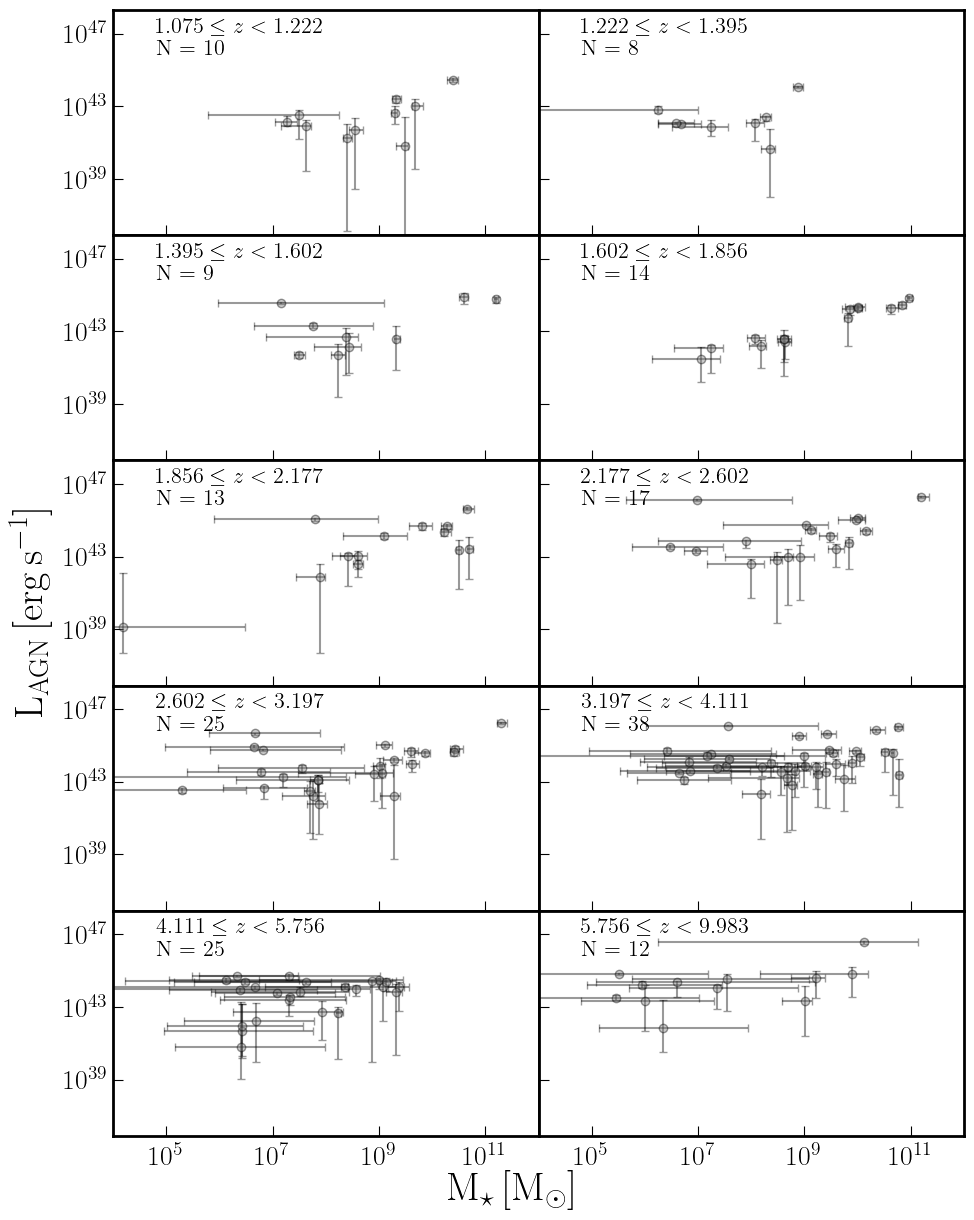

In [120]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["AGNlumQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["AGNlum_lo"][zidx], prospect_sample["AGNlum_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([8e35, 2e48])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{L_{AGN} \, [erg \, s^{-1}]}$", x = -0.06)

# fig.savefig(
#     "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Mstar vs MUV

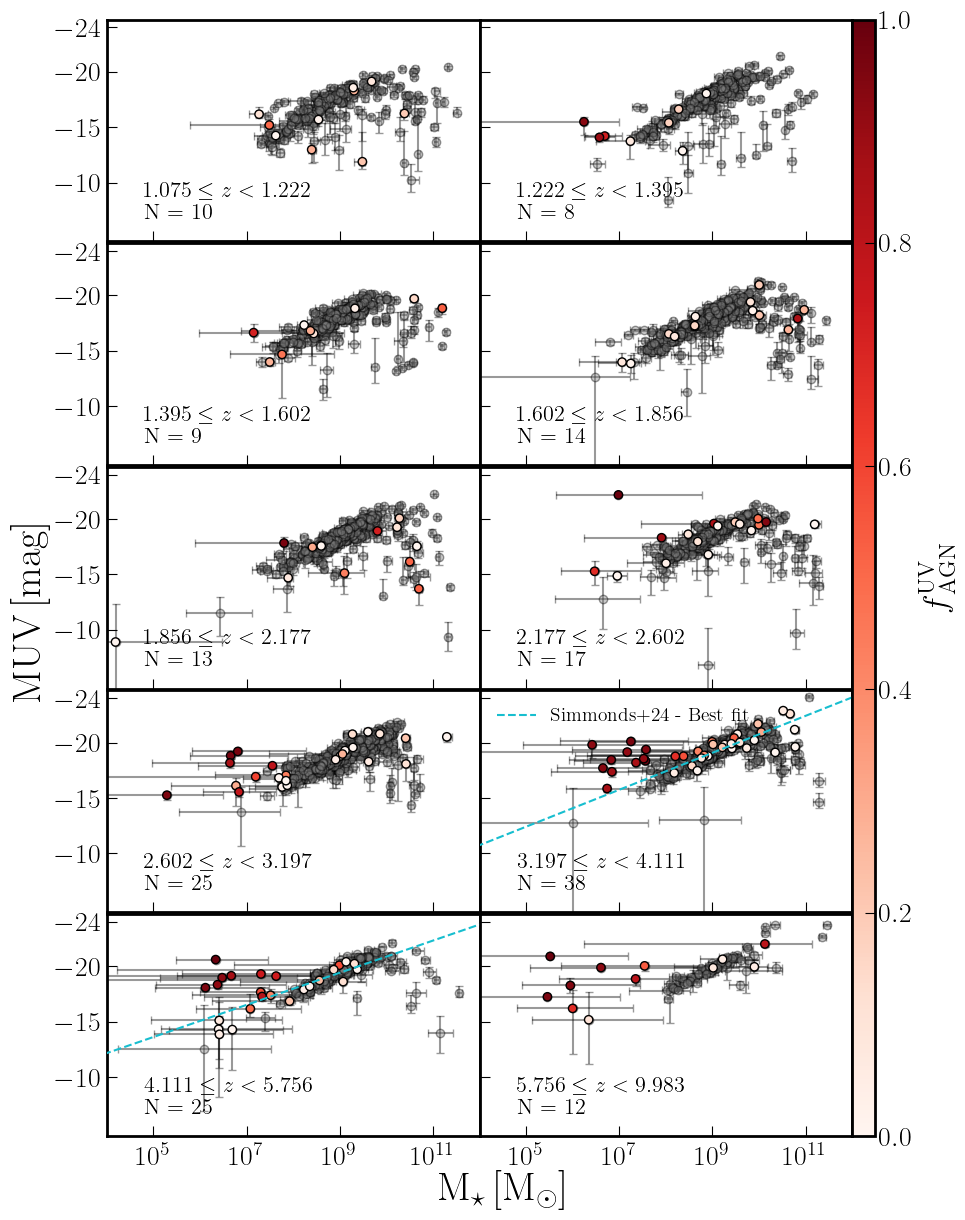

In [110]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

MUV_AGN_ratio = pow(10, -0.4 * (prospect_sample["UV1500AGNQ50"] - prospect_sample["UV1500Q50"]))

xMstar = np.linspace(1.5, 15.5, 100)

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["UV1500_lo"][zidx], prospect_sample["UV1500_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        c = MUV_AGN_ratio[zidx],
        edgecolor = "black",
        vmin = 0.0,
        vmax = 1.0,
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )

    if i == 7:
        ax[i].plot(
            10**xMstar,
            (xMstar - 9.25)/-0.6 - 19.5,
            color = "tab:cyan",
            ls = "--",
            label = "Simmonds+24 - Best fit",
            zorder = 200
        )
        ax[i].legend(
            fontsize = 14,
            frameon = False,
            loc = "upper left"
        )
    if i == 8:
        ax[i].plot(
            10**xMstar,
            (xMstar - 9.06)/-0.69 - 19.5,
            color = "tab:cyan",
            ls = "--",
            label = "Simmonds+24 - Best fit",
            zorder = 200
        )

    ax[i].text(
        0.1,
        0.2,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.1,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].set_xscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([-4.7, -24.7])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([-10, -15, -20, -24])

cbar = fig.colorbar(sc_, ax = ax, label=r'$f\mathrm{_{AGN}^{UV}}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{MUV \, [mag]}$", x = -0.05)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/MUV-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

Text(-0.05, 0.5, '$\\mathrm{MUV \\, [mag]}$')

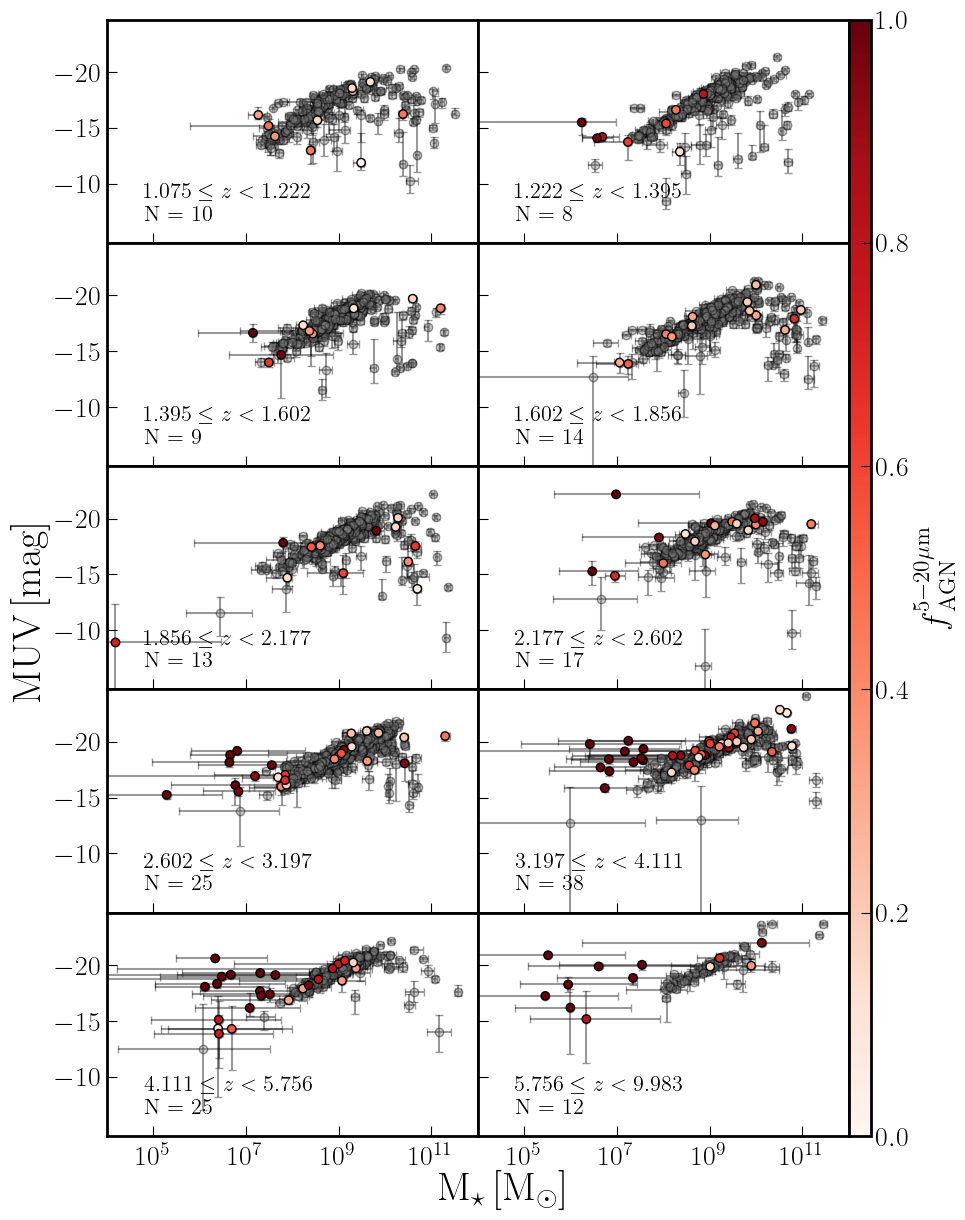

In [111]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

MUV_AGN_ratio = pow(10, -0.4 * (prospect_sample["UV1500AGNQ50"] - prospect_sample["UV1500Q50"]))

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["UV1500_lo"][zidx], prospect_sample["UV1500_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        c = [np.nan if x == 0 else x for x in prospect_sample["AGN_Dale_frac_Q50"][zidx]],
        edgecolor = "black",
        vmin = 0.0,
        vmax = 1.0,
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )
    ax[i].text(
            0.1,
            0.2,
            rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
            transform=ax[i].transAxes,
            fontsize = 16
    )
    ax[i].text(
        0.1,
        0.1,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].set_xscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([-4.7, -24.7])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([-10, -15, -20])

cbar = fig.colorbar(sc_, ax = ax, label=r'$f\mathrm{_{AGN}^{5-20\mu m}}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{MUV \, [mag]}$", x = -0.05)

# fig.savefig(
#     "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Mstar vs. accretion rates

In [112]:
from odrpack import odr_fit

In [117]:
BHAR_SFR_sample["BHARSFR10Q50"]

4       181.226348
5         0.000000
7         0.026328
8         0.000000
15        0.017294
           ...    
6943      0.014141
6948      0.000000
6949      0.000000
6953      0.000000
6962      0.000000
Name: BHARSFR10Q50, Length: 3230, dtype: float64

Keeping 8 of 216 points
slope, intercept: [ 0.00678186 -2.62181281]
uncertainties:    [0.10327459 0.8817123 ]
success: True - Sum of squares convergence.
Keeping 7 of 267 points
slope, intercept: [ 0.72092951 -7.9944582 ]
uncertainties:    [0.41108174 3.55898525]
success: True - Sum of squares convergence.
Keeping 8 of 277 points
slope, intercept: [ 0.29651103 -5.81791199]
uncertainties:    [0.09444471 0.96953036]
success: True - Sum of squares convergence.
Keeping 12 of 359 points
slope, intercept: [-0.08896332 -1.62667611]
uncertainties:    [0.07484728 0.74163689]
success: True - Sum of squares convergence.
Keeping 10 of 372 points
slope, intercept: [ 0.4823038  -7.04953175]
uncertainties:    [0.24813262 2.5560735 ]
success: True - Sum of squares convergence.
Keeping 16 of 309 points
slope, intercept: [ 0.30314543 -5.15980434]
uncertainties:    [0.10557871 1.14774876]
success: True - Sum of squares convergence.
Keeping 24 of 569 points
slope, intercept: [-0.27468038  0.57916657]
unce

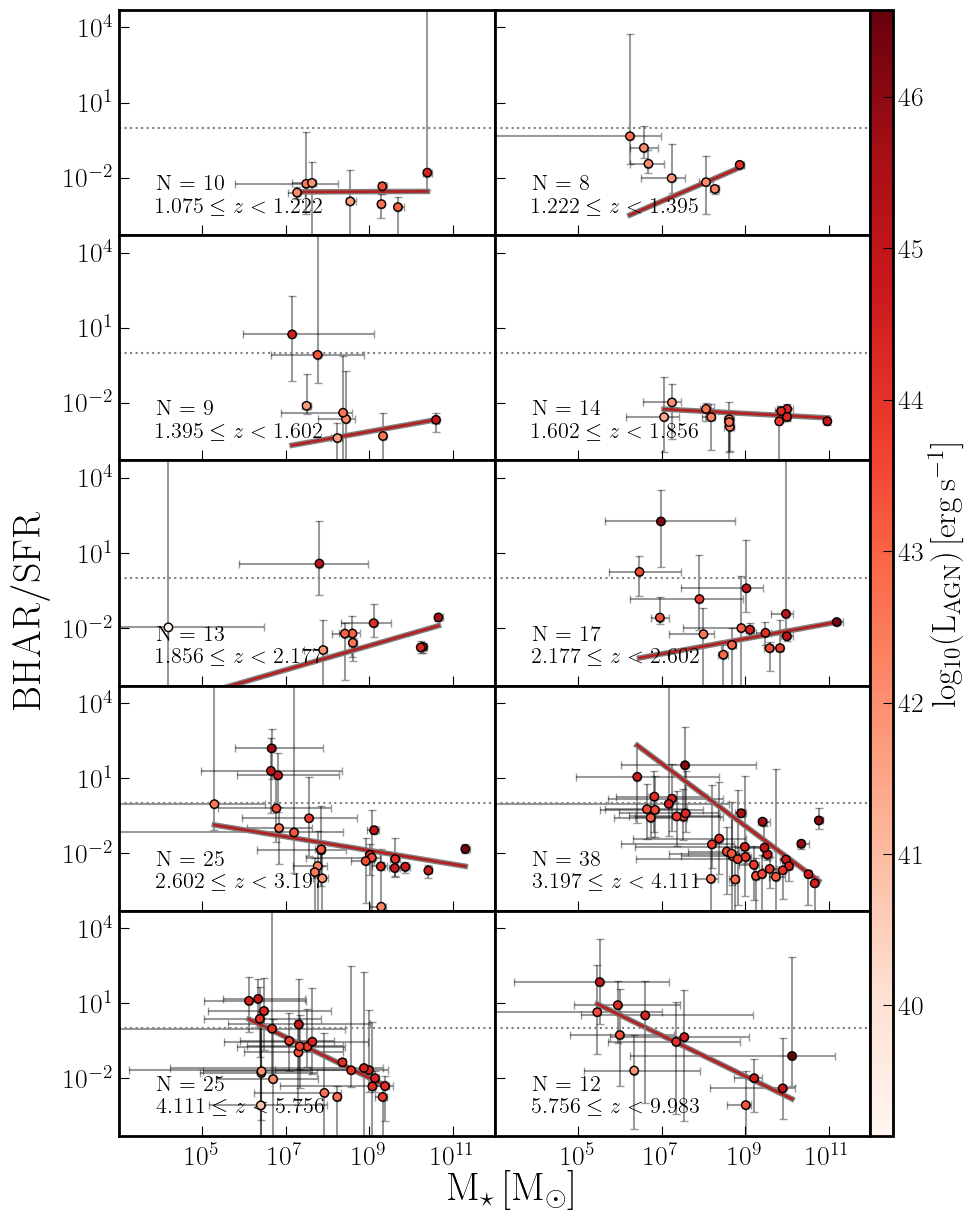

In [125]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1]) & (BHAR_SFR_sample["lowerlim"] == 0)
    zidx_quenched = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1]) & (BHAR_SFR_sample["lowerlim"] == 1)

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
       BHAR_SFR_sample["BHARSFR10Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [BHAR_SFR_sample["BHARSFR10_lo"][zidx], BHAR_SFR_sample["BHARSFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        BHAR_SFR_sample["BHARSFR10Q50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )

    # sc_quenched_ = ax[i].scatter(
    #     prospect_sample["StellarMassQ50"][zidx_quenched],
    #     BHAR_SFR_sample["lowerlimVal"][zidx_quenched],
    #     c = np.log10(quenched_sample["AGNlumQ50"][zidx_quenched]),
    #     # vmin = 41,
    #     # vmax = 47,
    #     vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
    #     vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
    #     zorder = 100, 
    #     cmap='Reds',
    #     alpha = 0.7,
    #     marker = up_arrow_marker,
    #     edgecolor = "firebrick",
    #     s = 800
    # )

    x = np.asarray(prospect_sample["StellarMassQ50"][zidx])
    y = np.asarray(BHAR_SFR_sample["BHARSFR10Q50"][zidx])

    x_lo = np.asarray(prospect_sample["StellarMass_lo"][zidx])
    x_hi = np.asarray(prospect_sample["StellarMass_hi"][zidx])
    y_lo = np.asarray(BHAR_SFR_sample["BHARSFR10_lo"][zidx])
    y_hi = np.asarray(BHAR_SFR_sample["BHARSFR10_hi"][zidx])

    mask = (
        np.isfinite(x) & np.isfinite(y) &
        np.isfinite(x_lo) & np.isfinite(x_hi) &
        np.isfinite(y_lo) & np.isfinite(y_hi) &
        (x > 0) & (y > 0)
    )

    print(f"Keeping {mask.sum()} of {len(x)} points")

    x, y = x[mask], y[mask]
    x_lo, x_hi = x_lo[mask], x_hi[mask]
    y_lo, y_hi = y_lo[mask], y_hi[mask]

    # then redo the log transform + error propagation + fit as before
    logx = np.log10(x)
    logy = np.log10(y)

    ln10 = np.log(10)
    logx_lo = x_lo / (x * ln10)
    logx_hi = x_hi / (x * ln10)
    logy_lo = y_lo / (y * ln10)
    logy_hi = y_hi / (y * ln10)

    logx_err = 0.5 * (logx_lo + logx_hi)
    logy_err = 0.5 * (logy_lo + logy_hi)

    weight_x = 1.0 / logx_err**2
    weight_y = 1.0 / logy_err**2

    def f(x, beta):
        m, b = beta
        return m * x + b

    beta0 = [1.0, 0.0]

    sol = odr_fit(f, logx, logy, beta0, weight_x=weight_x, weight_y=weight_y)

    # your fitted params from odrpack
    m, b = sol.beta

    # --- generate a smooth line across the x range ---
    x_fit = np.logspace(np.log10(x.min()), np.log10(x.max()), 200)
    y_fit = 10**b * x_fit**m

    ax[i].plot(
        x_fit, 
        y_fit, 
        lw = 2,
        color = "firebrick",
        label = "Fit",
        path_effects=[pe.Stroke(linewidth=4, foreground='grey'), pe.Normal()]
    )

    print("slope, intercept:", sol.beta)
    print("uncertainties:   ", sol.sd_beta)
    print("success:", sol.success, "-", sol.stopreason)

    ax[i].axhline(1, ls = ":", color = "grey")
    # ax[i].axvline(1e7, ls = "--", color = "grey", label = "Inayoshi+26")

    ax[i].text(
        0.1,
        0.1,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.2,
        f"N = { sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx])) + sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx_quenched]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([5e-5, 5e4])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

    # cbar = fig.colorbar(sc_, ax = ax[i])

    # ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# cbar_ax = fig.add_axes([0.87, 0.05, 0.02, 0.9])  # [left, bottom, width, height]
cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{BHAR / SFR}$", x = -0.06)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/bhar_sfr-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

# AGN fraction photometry

Text(0.02, 0.5, 'Fractional AGN contribution')

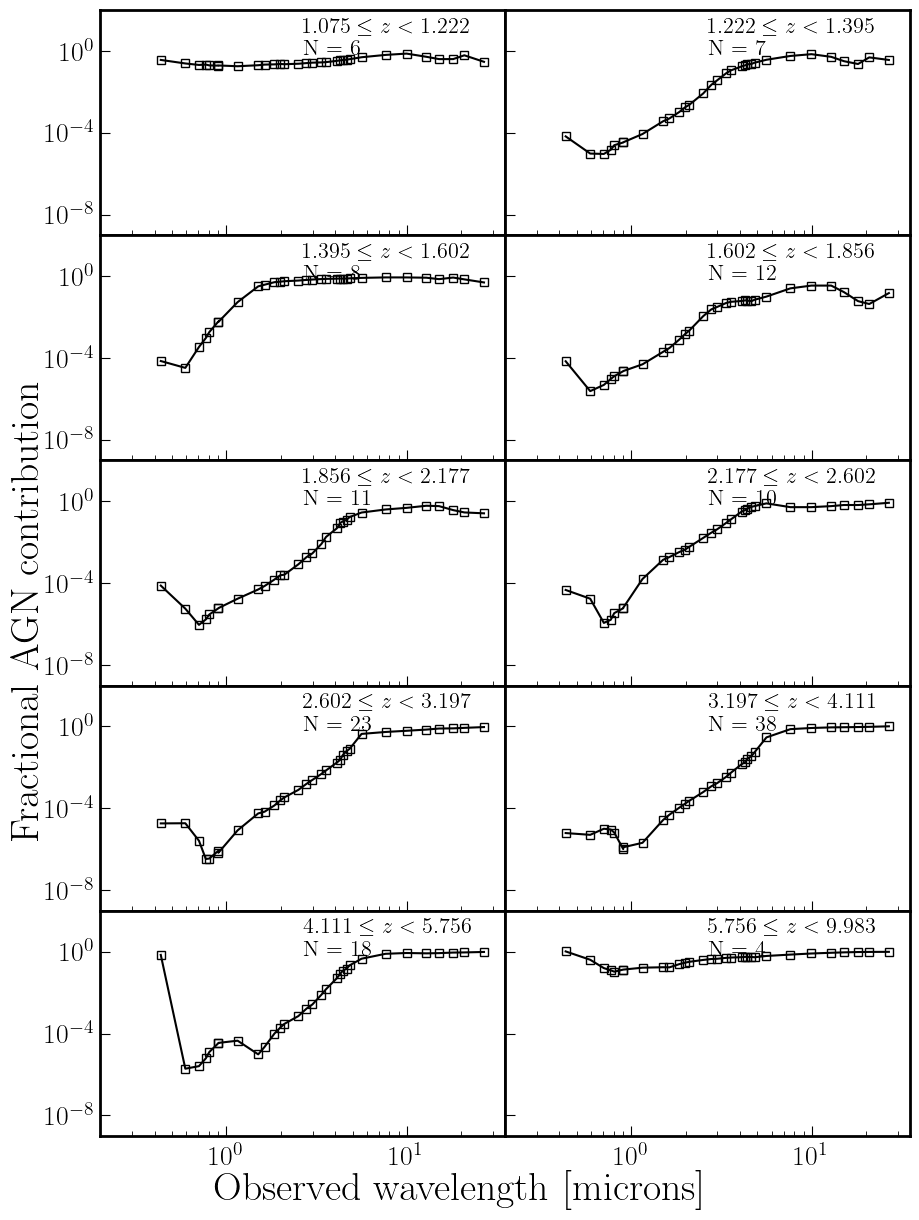

In [ ]:
q50_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_source_fit_Q50').columns.tolist()
AGN_q50_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_source_fit_AGN_Q50').columns.tolist()

q16_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_source_fit_Q16').columns.tolist()
AGN_q16_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_source_fit_AGN_Q16').columns.tolist()

q84_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_source_fit_Q84').columns.tolist()
AGN_q84_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_source_fit_AGN_Q84').columns.tolist()

fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

rng = np.random.default_rng(0)

for i in range(len(zmids)):

    zidx = (prospect_robust["zQ50"] >= zbins[i]) & (prospect_robust["zQ50"] < zbins[i+1]) & (prospect_robust["FitType"] == "StellarAGN")

    ff = prospect_robust_photom[zidx]

    # --- Step 2: build per-galaxy arrays: flux (q50), sigma (from q16/q84) ---
    q50 = ff[q50_cols].to_numpy()          # shape (N_gal, N_filt)
    sigma = 0.5 * (ff[q84_cols].to_numpy() - ff[q16_cols].to_numpy())
    q50_AGN = ff[AGN_q50_cols].to_numpy()          # shape (N_gal, N_filt)
    sigma_AGN = 0.5 * (ff[AGN_q84_cols].to_numpy() - ff[AGN_q16_cols].to_numpy())

    # optional: normalize each galaxy's SED (example: by median flux)
    # norm = np.nanmedian(q50, axis=1, keepdims=True)
    norm = 1.0
    q50_norm = q50 / norm
    sigma_norm = sigma / norm
    weights = sigma_norm ** -2

    # norm_AGN = np.nanmedian(q50_AGN, axis=1, keepdims=True)
    norm_AGN = 1.0
    q50_norm_AGN = q50_AGN / norm_AGN
    sigma_norm_AGN = sigma_AGN / norm_AGN
    weights_AGN = sigma_norm_AGN ** -2

    n_gal, n_filt = q50_norm.shape
    n_boot = 1000
    boot_stacks = np.zeros((n_boot, n_filt))

    for b in range(n_boot):
        idx = rng.integers(0, n_gal, n_gal)   # resample galaxies with replacement
        w = weights[idx]
        w_AGN = weights_AGN[idx]
        boot_stacks[b] = (np.nansum(q50_norm_AGN[idx] * w_AGN, axis=0) / np.nansum(w_AGN, axis=0)) / (np.nansum(q50_norm[idx] * w, axis=0) / np.nansum(w, axis=0))


    stack_16, stack_50, stack_84 = np.nanpercentile(boot_stacks, [16, 50, 84], axis=0)

    # diff = 0.5 * (ff[q84_cols].set_axis(q16_cols, axis=1) - ff[q16_cols])
    # diff_AGN = 0.5 * (ff[AGN_q84_cols].set_axis(AGN_q16_cols, axis=1) - ff[AGN_q16_cols])

    # ff_stack_err = np.sqrt(np.sum(
    #     (diff)**-2
    # )**-1)
    # ff_AGN_stack_err = np.sqrt(np.sum(
    #     (diff_AGN)**-2
    # )**-1)

    # yy_stack = np.average(ff[q50_cols], weights = (diff)**-2, axis = 0)
    # yy_AGN_stack = np.average(ff[AGN_q50_cols], weights = (diff_AGN)**-2, axis = 0)

    ax[i].plot(
        filters_info["cenwave"]/1e4, 
        stack_50,
        # np.nanmedian(ff[AGN_q50_cols], axis = 0) / np.nanmedian(ff[q50_cols], axis = 0),
        marker = "s",
        markerfacecolor = "none",
        color = "black"
    )

    # ax[i].errorbar(
    #     filters_info["cenwave"]/1e4, 
    #     yy_AGN_stack/yy_stack,
    #     yerr = [ np.sqrt( (yy_AGN_stack/yy_stack)**2 * ( (ff_stack_err/yy_stack)**2 + (ff_AGN_stack_err/yy_AGN_stack)**2 ) ) ],
    #     marker = "o",
    #     markerfacecolor = "grey",
    #     markeredgecolor = "black",
    #     color = "black",
    #     ecolor = "black", 
    #     alpha = 0.8,
    #     capsize = 3
    #     )
    # ax[i].plot(
    #     filters_info["cenwave"], 
    #     np.average(ff[AGN_q50_cols], weights = (0.5*diff_AGN)**-2, axis = 0),
    #     marker = "o",
    #     markerfacecolor = "none"
    # )
    ax[i].text(
        0.5,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.5,
        0.8,
        f"N = {sum(zidx)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')
    ax[i].set_xlim([0.2, 35])
    ax[i].set_ylim([1e-9, 100])
    ax[i].set_yticks([1e-8, 1e-4, 1.0])

fig.supxlabel(r"Observed wavelength $\mathrm{[microns]}$")
fig.supylabel(r"Fractional AGN contribution")



# Scratch

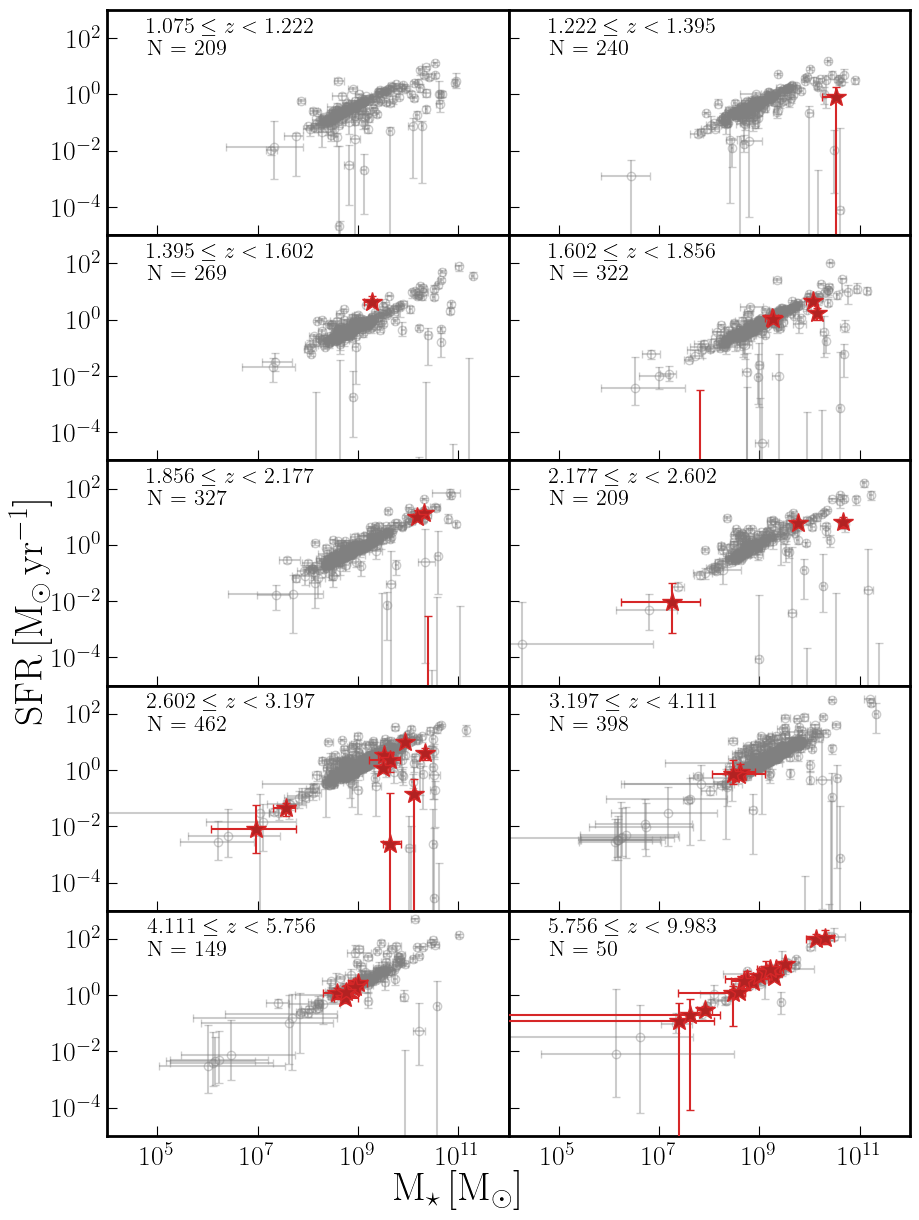

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

for i in range(len(zmids)):
    zidx = (prospect_robust["zQ50"] >= zbins[i]) & (prospect_robust["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_robust["StellarMassQ50"][zidx],
        prospect_robust["SFR10Q50"][zidx],
        xerr = [prospect_robust["StellarMass_lo"][zidx], prospect_robust["StellarMass_hi"][zidx]],
        yerr = [prospect_robust["SFR10_lo"][zidx], prospect_robust["SFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.4
    )

    ax[i].errorbar(
        prospect_lrd["StellarMassQ50"][zidx],
        prospect_lrd["SFR10Q50"][zidx],
        xerr = [prospect_lrd["StellarMass_lo"][zidx], prospect_lrd["StellarMass_hi"][zidx]],
        yerr = [prospect_lrd["SFR10_lo"][zidx], prospect_lrd["SFR10_hi"][zidx]],
        fmt = "*",
        markersize = 15,
        markerfacecolor = "firebrick",
        markeredgecolor = "tab:red",
        ecolor = "tab:red",
        capsize = 3, 
        zorder = 200
    )

    # sc_ = ax[i].scatter(
    #     prospect_robust["StellarMassQ50"][zidx],
    #     prospect_robust["SFR10Q50"][zidx],
    #     c = np.log10(prospect_robust["AGNlumQ50"][zidx]),
    #     zorder = 100, 
    #     cmap='Spectral_r',
    #     alpha = 0.5
    # )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        f"N = {sum(zidx)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    # ax[i].text(
    #     0.1,
    #     0.8,
    #     f"N - LRD = {sum(~np.isnan(prospect_lrd["StellarMassQ50"][zidx]))}",
    #     transform=ax[i].transAxes,
    #     fontsize = 16
    # )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([1e-5, 1e3])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# fig.colorbar(sc_, ax=ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.01)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR \, [M_{\odot} \, yr^{-1}]}$")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z_lrds.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


## Selected LRDs

In [ ]:
LRD_selection_idx = np.loadtxt("/Users/jordan/Documents/Epochs/data/prospect/LRD_colour_selection_IDs.txt")

[  30.   62.   71.   87.  147.  154.  212.  215.  220.  261.  316.  350.
  377.  382.  398.  435.  501.  542.  546.  585.  688.  806.  859.  866.
 1048. 1128. 1281. 1410. 1457. 1498. 1643. 1681. 1725. 1825. 1910. 2000.
 2152. 2257. 2268. 2342. 2549. 2588. 2628. 2843. 2846. 2968. 3169. 3444.
 3499. 3588. 3787. 3928. 3986. 4313. 4587. 4764. 4813. 4874. 5051.]


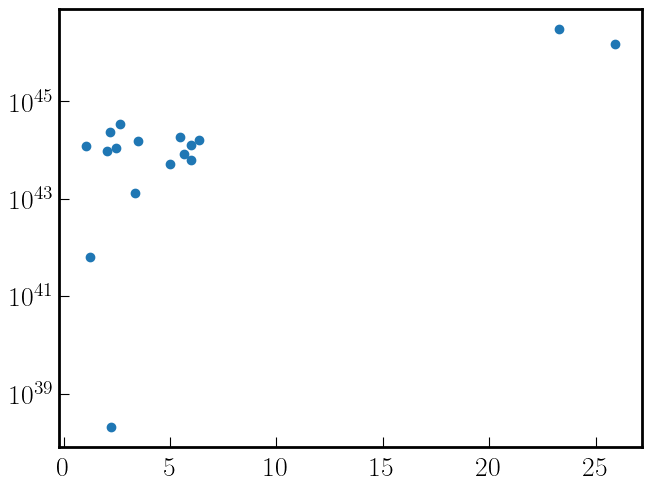

In [43]:
plt.scatter(prospect_robust["zQ50"][LRD_selection_idx-1],prospect_robust["AGNlumQ50"][LRD_selection_idx-1])
plt.yscale('log')

(1e+35, 1e+49)

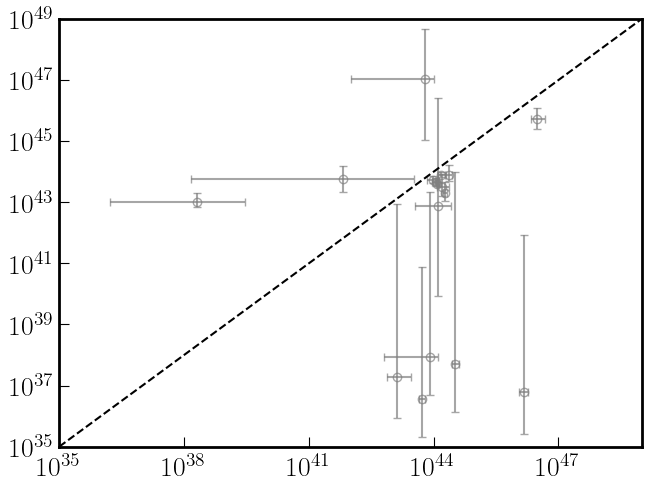

In [36]:
fig, ax = plt.subplots(1, 1)
ax.errorbar(
        prospect_robust["AGNlumQ50"],
        prospect_lrd["AGNlumQ50"],
        xerr = [prospect_robust["AGNlum_lo"], prospect_robust["AGNlum_hi"]],
        yerr = [prospect_lrd["AGNlum_lo"], prospect_lrd["AGNlum_hi"]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.7
    )
ax.plot(10**np.linspace(35,49,2), 10**np.linspace(35,49,2), color = "black", ls = "--")

# ax.hist(
#    np.log10(prospect_robust["AGNlumQ50"]) - np.log10(prospect_lrd["AGNlumQ50"]) 
# )

# print(f"Median = {np.nanmedian(np.log10(prospect_robust["AGNlumQ50"]) - np.log10(prospect_lrd["AGNlumQ50"])):.3}")
# fig.colorbar(sc_, ax=ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.01, ticks = [0,1])

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlim([1e35, 1e49])
ax.set_ylim([1e35, 1e49])

In [69]:
import re

# Get columns matching pattern like F435W_fit_Q50, F606W_fit_Q50 etc
q50_cols = [col for col in prospect_robust_photom.columns if re.search(r'F\d+W_fit_Q50', col)]
# Or with pandas filter
q50_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_fit_Q50').columns.tolist()
AGN_q50_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_fit_AGN_Q50').columns.tolist()

print(AGN_q50_cols)

# mask = (prospect_robust_photom[AGN_q50_cols] > 0).all(axis=1)

['HST_ACSWFC_F435W_fit_AGN_Q50', 'HST_ACSWFC_F606W_fit_AGN_Q50', 'JWST_NIRCAM_F070W_fit_AGN_Q50', 'HST_ACSWFC_F775W_fit_AGN_Q50', 'HST_ACSWFC_F814W_fit_AGN_Q50', 'JWST_NIRCAM_F090W_fit_AGN_Q50', 'HST_ACSWFC_F850LP_fit_AGN_Q50', 'JWST_NIRCAM_F115W_fit_AGN_Q50', 'JWST_NIRCAM_F150W_fit_AGN_Q50', 'JWST_NIRCAM_F162M_fit_AGN_Q50', 'JWST_NIRCAM_F182M_fit_AGN_Q50', 'JWST_NIRCAM_F200W_fit_AGN_Q50', 'JWST_NIRCAM_F210M_fit_AGN_Q50', 'JWST_NIRCAM_F250M_fit_AGN_Q50', 'JWST_NIRCAM_F277W_fit_AGN_Q50', 'JWST_NIRCAM_F300M_fit_AGN_Q50', 'JWST_NIRCAM_F335M_fit_AGN_Q50', 'JWST_NIRCAM_F356W_fit_AGN_Q50', 'JWST_NIRCAM_F410M_fit_AGN_Q50', 'JWST_NIRCAM_F430M_fit_AGN_Q50', 'JWST_NIRCAM_F444W_fit_AGN_Q50', 'JWST_NIRCAM_F460M_fit_AGN_Q50', 'JWST_NIRCAM_F480M_fit_AGN_Q50', 'JWST_MIRI_F560W_fit_AGN_Q50', 'JWST_MIRI_F770W_fit_AGN_Q50', 'JWST_MIRI_F1000W_fit_AGN_Q50', 'JWST_MIRI_F1280W_fit_AGN_Q50', 'JWST_MIRI_F1500W_fit_AGN_Q50', 'JWST_MIRI_F1800W_fit_AGN_Q50', 'JWST_MIRI_F2100W_fit_AGN_Q50', 'JWST_MIRI_F2550W_fit_

ValueError: x and y must be the same size

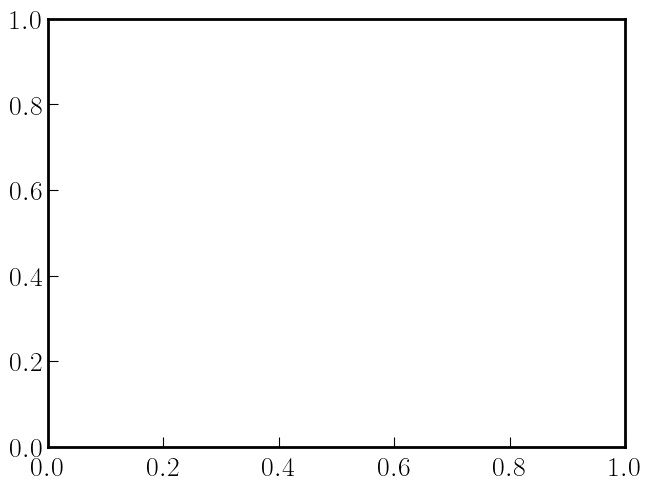

In [45]:
plt.scatter(filters_info["cenwave"], np.sum(prospect_robust_photom[AGN_q50_cols], axis = 0)/np.sum(prospect_robust_photom[q50_cols], axis = 0))
# plt.scatter(filters_info["cenwave"], np.sum(prospect_robust_photom[AGN_q50_cols], axis = 0))
# plt.yscale("log")
plt.xscale("log")

In [46]:
prospect_robust_photom[AGN_q50_cols][mask]

,HST_ACSWFC_F435W_fit_AGN_Q50,HST_ACSWFC_F606W_fit_AGN_Q50,JWST_NIRCAM_F070W_fit_AGN_Q50,HST_ACSWFC_F775W_fit_AGN_Q50,HST_ACSWFC_F814W_fit_AGN_Q50,JWST_NIRCAM_F090W_fit_AGN_Q50,HST_ACSWFC_F850LP_fit_AGN_Q50,JWST_NIRCAM_F115W_fit_AGN_Q50,JWST_NIRCAM_F150W_fit_AGN_Q50,JWST_NIRCAM_F162M_fit_AGN_Q50,...,JWST_NIRCAM_F460M_fit_AGN_Q50,JWST_NIRCAM_F480M_fit_AGN_Q50,JWST_MIRI_F560W_fit_AGN_Q50,JWST_MIRI_F770W_fit_AGN_Q50,JWST_MIRI_F1000W_fit_AGN_Q50,JWST_MIRI_F1280W_fit_AGN_Q50,JWST_MIRI_F1500W_fit_AGN_Q50,JWST_MIRI_F1800W_fit_AGN_Q50,JWST_MIRI_F2100W_fit_AGN_Q50,JWST_MIRI_F2550W_fit_AGN_Q50
0,4.491524e-08,8.912835e-08,1.308900e-07,1.555717e-07,1.707938e-07,2.113829e-07,2.132751e-07,3.381780e-07,5.543457e-07,6.281284e-07,...,4.431554e-06,4.944024e-06,6.221892e-06,9.227331e-06,1.182161e-05,1.603996e-05,2.095900e-05,2.606452e-05,2.873978e-05,3.121301e-05
4,9.802393e-36,5.334136e-42,5.264137e-43,3.290155e-40,3.247677e-37,2.252588e-21,3.235885e-21,5.556744e-21,5.726362e-10,6.540823e-10,...,7.517888e-09,7.870375e-09,9.937514e-09,1.546761e-08,2.280038e-08,3.219257e-08,4.297427e-08,5.682462e-08,6.874615e-08,9.605409e-08
7,3.322940e-14,9.951388e-14,5.264344e-13,1.376773e-12,5.081697e-12,1.721831e-11,1.717241e-11,8.167963e-11,3.053658e-10,4.747523e-10,...,8.824740e-07,1.137454e-06,2.668135e-06,8.488463e-06,1.611274e-05,2.353557e-05,2.760480e-05,3.066751e-05,2.601841e-05,3.157209e-05
9,3.771602e-08,8.720459e-08,1.345362e-07,1.673704e-07,1.943275e-07,2.679791e-07,2.700405e-07,5.352922e-07,1.206017e-06,1.401509e-06,...,1.293423e-05,1.222337e-05,1.376680e-05,1.813391e-05,2.633656e-05,3.188313e-05,3.525410e-05,3.415639e-05,3.167952e-05,3.944913e-05
10,6.213965e-13,8.738172e-13,1.056022e-12,1.152295e-12,1.199950e-12,1.367779e-12,1.389633e-12,2.204576e-12,3.673682e-12,4.641191e-12,...,2.231209e-11,2.367015e-11,2.699412e-11,3.673070e-11,5.590185e-11,5.836728e-11,6.237555e-11,5.385159e-11,6.340536e-11,7.706384e-11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5637,4.315020e-10,1.634381e-09,2.144248e-09,2.257249e-09,2.299706e-09,2.420009e-09,2.424879e-09,2.750457e-09,3.532368e-09,3.798678e-09,...,9.926930e-09,1.042024e-08,1.236252e-08,1.802558e-08,2.526186e-08,3.296133e-08,3.846250e-08,4.429749e-08,4.866426e-08,5.423687e-08
5662,2.015765e-20,2.732256e-17,4.680400e-17,1.396848e-16,1.724805e-16,1.992465e-16,1.999333e-16,2.428437e-16,2.969182e-16,3.209928e-16,...,1.292401e-15,1.357194e-15,1.607515e-15,2.374117e-15,3.433727e-15,4.977049e-15,6.308144e-15,8.342047e-15,1.051845e-14,1.405314e-14
5663,6.410117e-13,9.333567e-13,1.050578e-12,1.111055e-12,1.129859e-12,1.192976e-12,1.201361e-12,1.373330e-12,1.587628e-12,1.635696e-12,...,3.139787e-12,3.303919e-12,3.891392e-12,5.469430e-12,7.155733e-12,8.669648e-12,9.608354e-12,1.080229e-11,1.151574e-11,1.437550e-11
5664,4.450798e-09,5.924091e-09,7.146839e-09,7.718800e-09,8.035030e-09,9.068117e-09,9.111977e-09,1.164606e-08,1.562033e-08,1.709116e-08,...,5.719618e-08,5.841444e-08,6.423047e-08,7.430648e-08,8.327158e-08,1.466486e-07,1.367442e-07,1.009205e-07,1.025400e-07,1.223824e-07


(1e-10, 0.001)

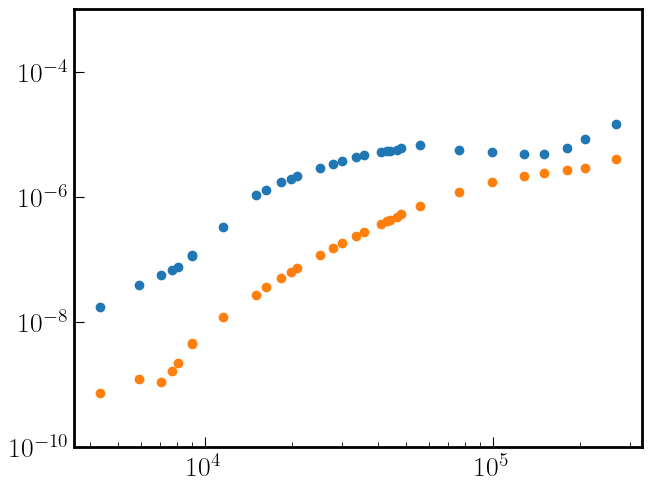

In [56]:
plt.scatter(
    filters_info["cenwave"], 
    prospect_robust_photom.iloc[29][q50_cols]
)
plt.scatter(
    filters_info["cenwave"], 
    prospect_robust_photom.iloc[29][AGN_q50_cols]
)

plt.xscale("log")
plt.yscale("log")
plt.ylim([1e-10, 1e-3])

# For Rosa

0      1
1      2
2      3
3      4
4      5
      ..
84    85
85    86
86    87
87    88
88    89
Name: CATINDEX, Length: 89, dtype: int64
0      1
1      2
2      3
3      4
4      5
      ..
83    85
84    86
85    87
86    88
87    89
Name: CATINDEX, Length: 88, dtype: int64
IDs in rosa_heII: 32
IDs in plots: False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, True, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False


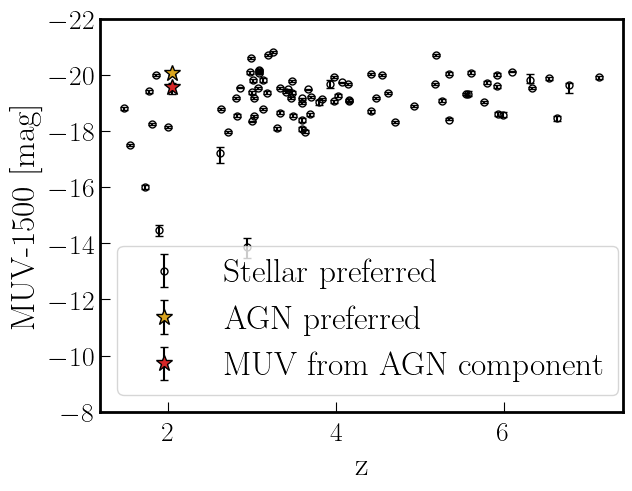

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Load data ---

main_dir = "~/mnt/morgan/raid/" # replace with /raid/scratch/work/jdsilva/ for example
rosa_heII = pd.read_csv(os.path.expanduser(main_dir + "forRosa/data/subset_HeII.csv"))
rosa_heII["CATINDEX"] = np.arange(1, len(rosa_heII) + 1)

rosa_df = pd.read_csv(os.path.expanduser(main_dir + "/forRosa/data/rosa_HeII_photom.csv"))

astro_bc03_snorm = pd.read_csv(
    os.path.expanduser(main_dir + "/forRosa/data/prospect/bc03_snorm_astro_cat.csv")
)
astro_bc03_snorm_fritz = pd.read_csv(
    os.path.expanduser(main_dir + "/forRosa/data/prospect/bc03_snorm_fritz_astro_cat.csv")
)
astro_bc03_snorm_fritz_type1 = pd.read_csv(
    os.path.expanduser(main_dir + "/forRosa/data/prospect/bc03_snorm_fritz_type1_astro_cat.csv")
)

print(rosa_heII["CATINDEX"])
print(astro_bc03_snorm["CATINDEX"])

# --- Compute UV ratio and AGN indices ---
UV_ratio = 10 ** (-0.4 * (astro_bc03_snorm_fritz["UV1500AGNQ50"] - astro_bc03_snorm_fritz["UV1500Q50"]))
AGN_idx = UV_ratio > 0.1  # select galaxies with more than 10% UV luminosity at 1500 angstrom coming from the AGN

# The above selection does not tell us if the inclusion of the AGN component improves the fit, 
# so we appeal to the Deviance Information Criterion (DIC) to select statistically significant preferred fit, prioritising lower DIC values
delta_DIC = astro_bc03_snorm["DIC"] - astro_bc03_snorm_fritz["DIC"]
AGN_idx = (UV_ratio > 0.1) & (delta_DIC >= 5.0)

# --- Print IDs ---
# print(rosa_df["file"].iloc[[70,88,33]])
print("IDs in rosa_heII: " + ", ".join(map(str, astro_bc03_snorm_fritz["CATINDEX"].iloc[AGN_idx])))
print("IDs in plots: " + ", ".join(map(str, AGN_idx)))
# print(rosa_heII["file"].iloc[[astro_bc03_snorm["CATINDEX"].iloc[AGN_idx] - 1]])

# --- Plot ---
fig, ax = plt.subplots()

ax.errorbar(
    astro_bc03_snorm["z"].iloc[~AGN_idx],
    astro_bc03_snorm["UV1500Q50"].iloc[~AGN_idx],
    yerr = [astro_bc03_snorm["UV1500_lo"].iloc[~AGN_idx], astro_bc03_snorm["UV1500_hi"].iloc[~AGN_idx]],
    markerfacecolor="none",
    markeredgecolor="black",
    ecolor = "black",
    label = "Stellar preferred",
    marker = "o",
    ls = "",
    alpha = 1.0,
    markersize = 5,
    capsize = 3
)
ax.errorbar(
    astro_bc03_snorm_fritz["z"].iloc[AGN_idx],
    astro_bc03_snorm_fritz["UV1500Q50"].iloc[AGN_idx],
    yerr = [astro_bc03_snorm_fritz["UV1500_lo"].iloc[AGN_idx], astro_bc03_snorm_fritz["UV1500_hi"].iloc[AGN_idx]],
    markerfacecolor="goldenrod",
    markeredgecolor="black",
    ecolor = "black",
    label = "AGN preferred",
    marker = "*",
    ls = "",
    alpha = 1.0,
    markersize = 12,
    capsize = 3
)
ax.errorbar(
    astro_bc03_snorm_fritz["z"].iloc[AGN_idx],
    astro_bc03_snorm_fritz["UV1500AGNQ50"].iloc[AGN_idx],
    yerr = [astro_bc03_snorm_fritz["UV1500AGN_lo"].iloc[AGN_idx], astro_bc03_snorm_fritz["UV1500AGN_hi"].iloc[AGN_idx]],
    markerfacecolor="tab:red",
    markeredgecolor="black",
    ecolor = "black",
    label = "MUV from AGN component",
    marker = "*",
    ls = "",
    alpha = 1.0,
    markersize = 12,
    capsize = 3
)
ax.legend()

ax.set_ylim(-8, -22) 
ax.set_xlabel("z")
ax.set_ylabel("MUV-1500 [mag]")

plt.show()

In [29]:
astro_bc03_snorm_fritz["UV1500_hi"].iloc[AGN_idx]

38    0.033072
65    0.043158
76    0.026892
Name: UV1500_hi, dtype: float64